### 1st cell

In [3]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from scipy.interpolate import RegularGridInterpolator

### 2nd PDE, grid and exact solution
Burgers: $u_t + a(u)\,u_x = \alpha u_{xx}$ with $a(u)=u$, on $[0,1]$, $u=0$ at both walls, $u(x,0)=\sin\pi x+\tfrac12\sin2\pi x$, $\alpha=0.1$.
Exact solution by Hopf–Cole: $u=-2\alpha\,\phi_x/\phi$, where $\phi$ solves the heat equation with $\phi_x=0$ at the walls (a cosine series).
The exact solution is only used to check results, never by the agent.

nx = 100, nt = 1090, dx = 0.01010, dt = 4.591e-04
max |u_true - u0| at t = 0: 3.4e-13
max |u| = 1.299 (A_MAX = 1.5)


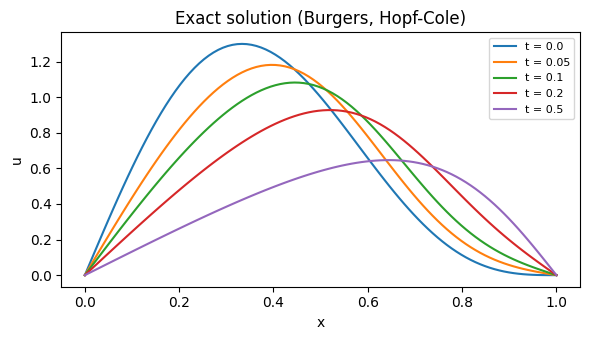

In [4]:
# ── PDE:  u_t + a(u) u_x = alpha u_xx   on [0, 1],  u = 0 at both walls ──
alpha = 0.1
a     = lambda u: u                            # advection speed: Burgers
A_MAX = 1.5                                    # bound on |u| (the IC peaks at about 1.26), for the CFL limit
u0    = lambda x: np.sin(np.pi * x) + 0.5 * np.sin(2 * np.pi * x)

# ── Grid ──
nx, T = 100, 0.5
dx = 1.0 / (nx - 1)
nt = int(np.ceil(T / min(0.9 * dx / A_MAX, 0.45 * dx**2 / alpha))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole): u = -2 alpha phi_x / phi, phi solves the heat equation with phi_x = 0 at the walls ──
# phi(x, 0) = exp(-(integral of u0 from 0 to x) / (2 alpha)), written as a cosine series
_xq   = np.linspace(0.0, 1.0, 20001)
_phi0 = np.exp(-((1 - np.cos(np.pi * _xq)) / np.pi + (1 - np.cos(2 * np.pi * _xq)) / (4 * np.pi)) / (2 * alpha))
_n    = np.arange(0, 201)
_an   = np.array([(1 if k == 0 else 2) * np.trapezoid(_phi0 * np.cos(k * np.pi * _xq), _xq) for k in _n])

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    e = _an * np.exp(-alpha * (_n * np.pi)**2 * t)
    phi   = (np.cos(np.pi * np.outer(x, _n)) * e).sum(axis=1)
    phi_x = -(np.sin(np.pi * np.outer(x, _n)) * (e * _n * np.pi)).sum(axis=1)
    return -2 * alpha * phi_x / phi

print(f"nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e}")
print(f"max |u_true - u0| at t = 0: {np.abs(u_true(x_grid, 0.0) - u0(x_grid)).max():.1e}")
print(f"max |u| = {np.abs(u_true(x_grid, 0.0)).max():.3f} (A_MAX = {A_MAX})")

fig, ax = plt.subplots(figsize=(6, 3.5))
for tk in [0.0, 0.05, 0.1, 0.2, 0.5]:
    ax.plot(x_grid, u_true(x_grid, tk), label=f"t = {tk}")
ax.set_xlabel("x"); ax.set_ylabel("u"); ax.set_title("Exact solution (Burgers, Hopf-Cole)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3rd Cell

**Taylor predictor (thesis §2.5).** The value at a point $p$ is predicted from 5 neighbours $q$: $\hat u_p=\sum_q w_q u_q$.
Each neighbour sits at an offset from $p$: $\Delta x_q = x_q - x_p$ in space and $\Delta t_q = t_q - t_p$ in time ($\Delta t_q<0$, the neighbours are earlier).
Expanding each $u_q$ in a Taylor series about $p$ and replacing $u_t$ by the PDE ($u_t=\alpha u_{xx}-a\,u_x$, with the speed $a$ frozen at its value at $p$), the offsets only appear in the combination
$$\xi_q=\Delta x_q-a\,\Delta t_q ,$$
the neighbour's offset **in a frame moving with the flow** at speed $a$: a point that was carried to $p$ by the flow has $\xi=0$.
The weights then satisfy
$$\sum w=1,\qquad \sum w\,\xi=0,\qquad \sum w\left(\tfrac12\xi^2+\alpha\Delta t\right)=0 ,$$
i.e. the prediction is exact for the constant, the slope and the curvature terms.
We take the min-norm solution. A stencil is **admissible** if the rows have rank 3, cond $\le10^4$ and $\|w\|_1\le2$. The weights can be solved for many stencils at once.
Check: with 3 points one level down, the predictor is exactly Lax–Wendroff, for any local speed $a$.

In [5]:
# ── FD baselines on the full grid, run from the initial condition up to z* ──
#   FD-3 : central in space, forward Euler in time                (3 points, 1st order in time)
#   LW   : Lax-Wendroff with the local speed a(u)                  (3 points, 2nd order)
#   FD-5 : 4th-order central in space, forward Euler, 3-point next to the walls (5 points)
#          explicit FD-5 is unstable at our dt (needs r <= 3/8), so it runs with dt/2
def fd_step(u, scheme, k):
    """One time step of size k."""
    r, ui = alpha * k / dx**2, u[1:-1]
    nu = a(ui) * k / dx
    n = u.copy()
    n[1:-1] = ui + r * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    if scheme == "LW":
        n[1:-1] += nu**2 / 2 * (u[2:] - 2 * ui + u[:-2])
    if scheme == "FD-5":
        v, nu = u[2:-2], a(u[2:-2]) * k / dx
        n[2:-2] = (v + r * (-u[4:] + 16 * u[3:-1] - 30 * v + 16 * u[1:-3] - u[:-4]) / 12
                     - nu * (-u[4:] + 8 * u[3:-1] - 8 * u[1:-3] + u[:-4]) / 12)
    n[0] = n[-1] = 0.0
    return n

FD_SCHEMES = {"FD-3": (1, 3), "LW": (1, 3), "FD-5": (2, 5)}   # (sub-steps per dt, neighbours per point)
_fd_cache = {}
def fd_reference(ix, it, scheme):
    """Baseline at z* = (ix, it): value, error, computed points in the cone below z*, work = points x neighbours."""
    key = (ix, it, scheme)
    if key not in _fd_cache:
        sub, n_nb = FD_SCHEMES[scheme]
        u = u_true(x_grid, 0.0)                     # same initial data the map will use
        for _ in range(it * sub):
            u = fd_step(u, scheme, dt / sub)
        err = abs(u[ix] - u_true(ix * dx, it * dt)[0])
        s = n_nb // 2                               # the cone widens by s cells per level
        n_pts = sum(min(nx - 2, ix + s * j) - max(1, ix - s * j) + 1 for j in range(it * sub))
        _fd_cache[key] = (u[ix], err, n_pts, n_pts * n_nb)
    return _fd_cache[key]

print(f"r = alpha dt/dx^2 = {alpha * dt / dx**2:.3f}")
for z in [(50, 20), (50, 100)]:
    for scheme in FD_SCHEMES:
        _, err, n_pts, work = fd_reference(*z, scheme)
        print(f"z* = {z}  {scheme:5s}: error {err:.2e}, {n_pts:5d} points, work {work:6d}")

# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

a_p = 1.0                                       # local speed at p (Burgers: a = u at p); any value works here
r, nu = alpha * dt / dx**2, a_p * dt / dx
w3 = solve_weights(np.array([-1, 0, 1]) * dx, np.array([-1, -1, -1]) * dt, a_p)
print("3 points one level down:", np.round(w3, 5))
print("Lax-Wendroff weights:   ", np.round([r + nu/2 + nu**2/2, 1 - 2*r - nu**2, r - nu/2 + nu**2/2], 5))

r = alpha dt/dx^2 = 0.450
z* = (50, 20)  FD-3 : error 4.28e-05,   400 points, work   1200
z* = (50, 20)  LW   : error 1.85e-05,   400 points, work   1200
z* = (50, 20)  FD-5 : error 3.06e-05,  2695 points, work  13475
z* = (50, 100)  FD-3 : error 3.03e-04,  7399 points, work  22197
z* = (50, 100)  LW   : error 8.77e-05,  7399 points, work  22197
z* = (50, 100)  FD-5 : error 1.80e-04, 18375 points, work  91875
3 points one level down: [0.47376 0.09793 0.42831]
Lax-Wendroff weights:    [0.47376 0.09793 0.42831]


### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value $u_q$ in a Taylor series around $p$ (and using $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
where $P_p$ is the Taylor polynomial of $u$ around $p$, kept up to weight 4 (a $\Delta t$ counts like two $\Delta x$'s, since $\alpha\Delta t\sim\Delta x^2$):
$$P_p=u_x\Delta x+u_t\Delta t+\tfrac12u_{xx}\Delta x^2+u_{xt}\Delta x\Delta t+\tfrac12u_{tt}\Delta t^2+\tfrac16u_{xxx}\Delta x^3+\tfrac12u_{xxt}\Delta x^2\Delta t+\tfrac1{24}u_{xxxx}\Delta x^4 .$$
Every time derivative is replaced using Burgers ($u_t=\alpha u_{xx}-u\,u_x$), so only the space derivatives $u,u_x,\dots,u_{xxxx}$ at $p$ are needed:

| | |
|---|---|
| $u_t$ | $\alpha u_{xx}-u\,u_x$ |
| $u_{xt}$ | $\alpha u_{xxx}-u\,u_{xx}-u_x^2$ |
| $u_{xxt}$ | $\alpha u_{xxxx}-u\,u_{xxx}-3u_xu_{xx}$ |
| $u_{tt}$ | $\alpha^2u_{xxxx}-2\alpha u\,u_{xxx}+u^2u_{xx}+2u_x(u\,u_x-2\alpha u_{xx})$ |

The terms with $u_x^2$ and $u_xu_{xx}$ come from the nonlinear term: the speed $u$ changes across the stencil. A score built for the linear equation (frozen speed) misses them.
Check: random admissible stencils at random points below $z^*$, with the **exact** derivatives (from the exact solution), score against the true local error.

300 admissible stencils, local speed a from 0.47 to 1.29
corr(log score, log true error) = 1.00, median |score - true error| / true error = 0.02


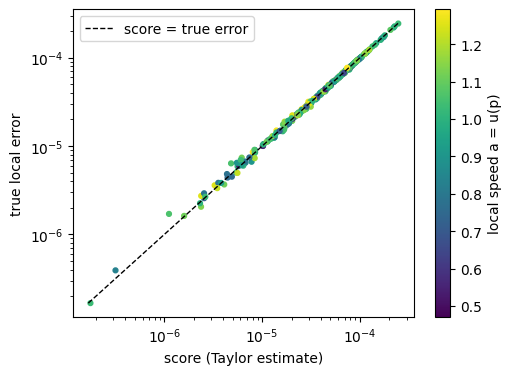

In [6]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients with every time derivative replaced using Burgers, u_t = alpha u_xx - u u_x
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, for random admissible stencils at random points p in z* = (50, 20)'s cone ──
# here the speed a = u(p) and the derivatives are exact (u_true ONLY for this check)
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]               # 3 levels down, |dix| <= 3
S, D, A = [], [], []
while len(S) < 300:
    it = int(rng.integers(3, 21))
    p = (int(rng.integers(50 - (20 - it), 50 + (20 - it) + 1)), it)        # a point in the cone below z*
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)
    w = solve_weights(DX, DT, d[0])
    if w is None:
        continue
    u_nb = np.array([u_true((p[0] + q[0]) * dx, (p[1] + q[1]) * dt)[0] for q in nb])
    S.append(score(DX, DT, w, d)); A.append(d[0])
    D.append(abs(u_true(p[0] * dx, p[1] * dt)[0] - w @ u_nb))
S, D, A = np.array(S), np.array(D), np.array(A)
print(f"300 admissible stencils, local speed a from {A.min():.2f} to {A.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=A, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local speed a = u(p)")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

### Rough guess of u and its derivatives
To build the map backward, every point needs, before any value has been computed:
- its local speed $a=u$ (for the weights), and
- the space derivatives $u,u_x,\dots,u_{xxxx}$ (for the score, cell 4).

We take them from a cheap **coarse solve**: Lax–Wendroff on a grid 5× coarser, from the initial condition to $T$, computed once for all queries. At each coarse time, a sine series is fitted through the coarse values ($u=0$ at both walls), which gives the derivatives exactly for the fit. In time we interpolate linearly onto our grid.
The guess only steers **which stencils and weights are chosen**. The values at $z^*$ are computed from the neighbours' values, so a poor guess gives worse choices, never wrong numbers. Its cost (840 points) is added to the method's cost.

coarse grid: 20 x 42 = 840 points (dx 0.0526, dt 1.22e-02)
z* = (50, 20): max error / max size in the cone, for u, u_x, u_xx, u_xxx, u_xxxx: 0.000  0.001  0.002  0.011  0.011
z* = (50, 100): max error / max size in the cone, for u, u_x, u_xx, u_xxx, u_xxxx: 0.008  0.015  0.032  0.062  0.122


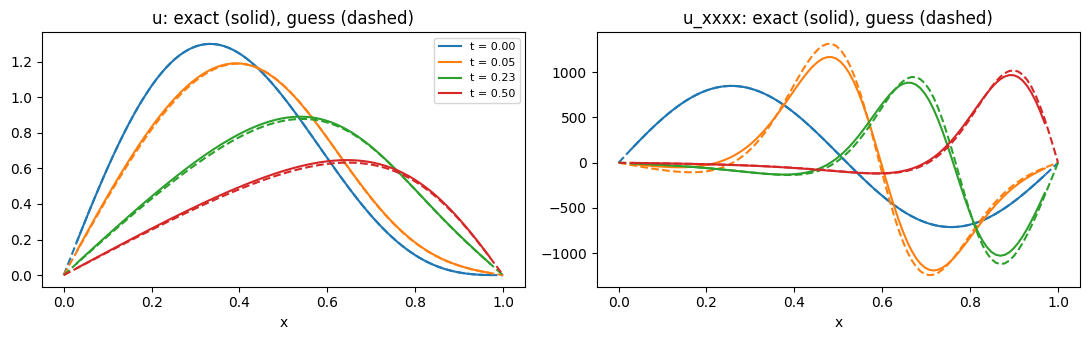

In [7]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score, influence) ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the initial condition to T, computed once for all queries.
K_COARSE = 5
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
tau = T / int(np.ceil(T / min(0.45 * hc**2 / alpha, 0.9 * hc / A_MAX)))      # CFL step of the coarse grid
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
for _ in tc[1:]:
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, a(ui) * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    n[0] = n[-1] = 0.0
    Uc.append(n)
G_COARSE = len(xc) * len(tc)                                                  # cost of the guess (grid points)

# ── Smooth fit in x at each coarse time: a sine series through the coarse values (u = 0 at both walls) ──
# its k-th x-derivative is exact for the fit: d^k/dx^k sin(m pi x) = (m pi)^k sin(m pi x + k pi/2)
modes = np.arange(1, len(xc) - 1)
Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    b = np.linalg.solve(np.sin(np.pi * np.outer(xc[1:-1], modes)), u[1:-1])
    for k in range(5):
        Dc[k, j] = ((modes * np.pi)**k * b * np.sin(np.pi * np.outer(x_grid, modes) + k * np.pi / 2)).sum(1)

# ── Linear in time onto our grid: GUESS[k, it, ix] = k-th x-derivative of the guess at grid point (ix, it) ──
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f  = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                 # (u, u_x, u_xx, u_xxx, u_xxxx) at q

# ── Check against the exact solution in the cone below z* (u_true ONLY for this check) ──
print(f"coarse grid: {len(xc)} x {len(tc)} = {G_COARSE} points (dx {hc:.4f}, dt {tau:.2e})")
for z in [(50, 20), (50, 100)]:
    cone = [(ix, it) for it in range(1, z[1] + 1) for ix in range(max(1, z[0] - (z[1] - it)), min(nx - 2, z[0] + (z[1] - it)) + 1)]
    ex = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in cone])
    gs = np.array([guess_derivs(q) for q in cone])
    rel = np.abs(gs - ex).max(0) / np.abs(ex).max(0)
    print(f"z* = {z}: max error / max size in the cone, for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{r:.3f}" for r in rel))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, it in enumerate([0, 100, 500, nt - 1]):
    ex = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes, [0, 4]):
        ax.plot(x_grid[3:-3], ex[:, k], color=f"C{i}", label=f"t = {it * dt:.2f}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
for ax in axes: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Backward map and influence β
**The map.** Start at $z^*$ and give it a stencil. Each neighbour that is not known data (IC or wall) becomes a new point that also needs a stencil. Repeat until every branch ends on the IC or a wall. Points are expanded **latest $t$ first**.

**Weights.** No values exist yet while building, so each point $p$ takes its speed from the guess (cell 5), $a_p=u_{\rm guess}(p)$, rounded to steps of 0.02 so the weights can be cached by (shape, speed). Its score uses the guessed derivatives at $p$ (cell 4).

**Influence.** $\beta_p$ = how much an error at $p$ changes the value at $z^*$. Start with $\beta_{z^*}=1$. When $p$ is expanded with weights $w$, pass its influence down: $\beta_q \mathrel{+}= \beta_p\,w_q$.

**Forward pass.** Values are computed bottom-up from the IC and walls, $\hat u_p=\sum_q w_q\hat u_q$, **with the weights chosen in the map**. Recomputing them with another speed would undo the choice: the score was computed for exactly these weights. The guess shapes the stencils and weights, but no guessed value enters $\hat u$.

**Exact identity.** With $\delta_p=u_p-\sum_q w_qu_q$ the local error,
$$e(z^*)=\sum_p\beta_p\,\delta_p .$$
Check: give every point the Lax–Wendroff stencil; the identity must hold to all digits.

In [8]:
# ── Known data: the initial condition and the walls are given, not computed ──
U0 = u_true(x_grid, 0.0)
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = lambda q: U0[q[0]] if q[1] == 0 else 0.0

# ── Speed at p for its weights: from the guess (cell 5), rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed)."""
    offs = tuple((q[0] - p[0], q[1] - p[1]) for q in nbs)
    key = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    return _w_cache[key]

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p (cell 4)."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded LATEST t first: every point that can use p is later
# than p, so it is already expanded and p's influence beta_p is complete when p is expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down: beta_q += beta_p * w_q."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if is_known(q):
            continue                                   # IC or wall: exact, the map stops here
        if q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
        m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p."""
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

# ── Forward pass: values bottom-up, from the IC and walls to z*, with the weights chosen in the map ──
def evaluate(m):
    u_hat = {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):          # increasing t: neighbours are ready
        nbs, w = m["stencil"][p]
        u_hat[p] = sum(wq * value(q) for q, wq in zip(nbs, w))
    return u_hat

# ── Check: every point takes the Lax-Wendroff stencil (3 points one level down) ──
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]
z = (50, 20)
m = build_map(z, lw)
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]                       # u_true ONLY for this check
err = U(z) - evaluate(m)[z]
delta = {p: U(p) - w @ np.array([U(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
print(f"LW map: {len(m['stencil'])} points | error at z*: map {abs(err):.2e}, FD LW (cell 3) {fd_reference(*z, 'LW')[1]:.2e}")
print(f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")

LW map: 400 points | error at z*: map 4.10e-05, FD LW (cell 3) 1.85e-05
identity: e(z*) = -4.097616e-05, sum beta*delta = -4.097616e-05


### Window, admissible stencils and the mask
**Window.** The candidate neighbours of $p$ are the 21 cells up to 3 to each side and 1 to 3 levels below $p$. A cell past a wall or below $t=0$ is moved onto the wall or the IC (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the admissibility test (cell 3), with $p$'s guessed speed. Points with the same local situation (distance to walls/IC) and the same guessed speed share one list, computed once and cached together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$. The score at a point is then just these moments times the Taylor coefficients at that point (cell 4): one small product per point.
**Mask.** The agent will pick the 5 cells one at a time. A cell may be picked next only if some admissible stencil contains it together with the picks so far, so the agent can never end up with a bad stencil.
**First rule without RL:** every point takes its lowest-score stencil. **Report** gives a finished map's points, its true error at $z^*$ and its exact bound $\sum_p|\beta_p\delta_p|$ (exact solution used only for reporting).

21 window cells | interior point (50, 20): 18694 admissible stencils of 20349
first pick allowed on 21 cells
LW          : 400 points, error 4.10e-05, exact bound 1.39e-04  (0 s)
lowest score: 613 points, error 4.42e-06, exact bound 9.37e-06  (10 s)


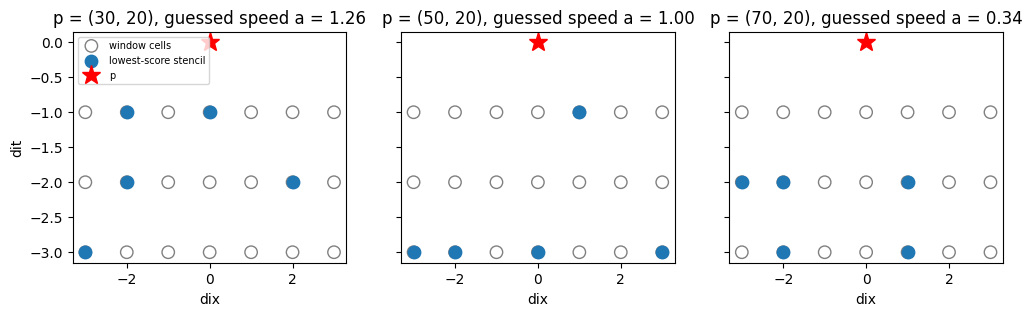

In [9]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)]
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score (cell 4)

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def pick_mask(p, picks):
    """Cell k may be picked next if some admissible stencil contains the picks so far plus k."""
    _, uses, _ = admissible(p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

# ── A first rule without RL: every point takes its lowest-score stencil ──
def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
def report(m):
    U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
    z = m["z_star"]
    delta = {p: U(p) - w @ np.array([U(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
    return {"points": len(m["stencil"]), "error": abs(U(z) - evaluate(m)[z]),
            "bound": sum(abs(m["beta"][p] * delta[p]) for p in delta)}

sets, _, sc = admissible((50, 20))
print(f"{N_CELLS} window cells | interior point (50, 20): {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))}")
print("first pick allowed on", pick_mask((50, 20), []).sum(), "cells")

z = (50, 20)
for name, rule in [("LW", lw), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(30, 20), (50, 20), (70, 20)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

### Environment
**Episode.** Build one map for the query $z^*$. At each step the agent picks one window cell for the current point (the latest-$t$ pending point). After 5 picks the stencil is complete, the point is expanded (cell 6), and the next point comes up. The episode ends when no points are pending.
**Mask.** Only cells that can still complete an admissible stencil are allowed (cell 7). Points with a single admissible stencil (next to the IC) are played automatically.
**Reward**, given each time a stencil is complete:
$$r_p=-\frac{|\beta_p|\,s_p}{B_{\rm LW}}-\lambda\,\frac{\text{new points}}{N_{\rm LW}},$$
where $s_p$ is the score (cell 4, with the guessed derivatives), and $B_{\rm LW}$, $N_{\rm LW}$ are the score sum and point count of the Lax–Wendroff map of the same $z^*$. So the total return is $-B/B_{\rm LW}-\lambda(N-1)/N_{\rm LW}$, and LW itself scores $\approx -1-\lambda$.
**Cap.** If the map grows past $3N_{\rm LW}$ points, the episode stops, and each point left unexpanded costs its worst stencil.
**State**, for the current point $p$:
- per window cell: already picked, already in the map (reusing it is free), known data (IC/wall), and the best score still reachable through it;
- and globally: $\log|\beta_p|$, levels above the IC, offset to $z^*$, pick number, points used so far, and the pending workload (points still waiting and their total influence).

In [10]:
# ── Reference for normalising the reward: the Lax-Wendroff map of the same z* ──
_ref_cache = {}
def reference(z):
    """(score sum, points) of LW's map. A return of -1 - lam means 'as good as LW'."""
    if z not in _ref_cache:
        m = build_map(z, lw)
        _ref_cache[z] = (sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"]), len(m["stencil"]))
    return _ref_cache[z]

# ── Environment: one step = one pick; a reward each time a stencil is complete ──
N_OBS = 4 * N_CELLS + 7

class MapEnv(gym.Env):
    def __init__(self, queries, lam=1.0, cap=3.0):
        super().__init__()
        self.queries, self.lam, self.cap = queries, lam, cap
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS)               # one action = one window cell

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z = self.queries[self.np_random.integers(len(self.queries))]
        self.B_ref, self.N_ref = reference(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self._play_forced()
        return self._obs(), {}

    def _complete(self, cells):
        """Expand the next point with these cells; reward = -|beta_p| s_p / B_ref - lam * new points / N_ref."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, w = expand(self.m, nbs)
        term = abs(self.m["beta"][p]) * point_score(p, nbs, w)
        self.B += term
        return -term / self.B_ref - self.lam * n_new / self.N_ref

    def _play_forced(self):
        """Points with only one admissible stencil (e.g. next to the IC) need no decision."""
        r = 0.0
        while self.m["pending"] and len(admissible(next_point(self.m))[0]) == 1:
            r += self._complete(admissible(next_point(self.m))[0][0])
        return r

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        picked, exists, known = np.zeros(N_CELLS), np.zeros(N_CELLS), np.zeros(N_CELLS)
        picked[self.picks] = 1
        for k in range(N_CELLS):
            q = place(p, k)
            known[k], exists[k] = is_known(q), q in self.m["beta"]      # exists = reusing it creates no new point
        # per cell: log10(best score still reachable through it / best score at p), capped at 3
        _, uses, sc = admissible(p)
        rel = np.log10(sc / sc.min())
        ok = uses[:, self.picks].all(axis=1) if self.picks else np.ones(len(rel), dtype=bool)
        reach = np.where(uses[ok], rel[ok, None], 3.0).min(axis=0)
        reach[self.picks] = 3.0
        pend = [(ix, -it) for it, ix in self.m["pending"]]
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1],                                              # levels above the IC
                p[0] - self.z[0],                                  # offset to z* in x
                len(self.picks),                                   # pick number
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend)]         # their total influence
        return np.concatenate([picked, exists, known, np.minimum(reach, 3.0), glob]).astype(np.float32)

    def step(self, k):
        self.picks.append(int(k))
        p = next_point(self.m)
        if len(self.picks) < len(admissible(p)[0][0]):             # still choosing p's stencil
            return self._obs(), 0.0, False, False, {}
        r = self._complete(self.picks)
        self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: each point left unexpanded costs its worst admissible stencil
        for it, ix in self.m["pending"]:
            q = (ix, -it)
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / self.B_ref
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]),
                "score_ratio": self.B / self.B_ref, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        return pick_mask(next_point(self.m), self.picks)

# ── Check: one episode with random (masked) picks ──
env = MapEnv(queries=[(50, 20)], lam=1.0)
obs, _ = env.reset(seed=0)
rng, total, steps, done = np.random.default_rng(0), 0.0, 0, False
while not done:
    obs, r, done, _, info = env.step(rng.choice(np.flatnonzero(env.action_masks())))
    total += r; steps += 1
print(f"obs size {N_OBS} | {steps} picks | finished: {info['finished']} | {info['points']} points "
      f"({info['points_ratio']:.2f}x LW) | score sum {info['score_ratio']:.1f}x LW")
print(f"sum of rewards {total:.3f}   check: -score_ratio - lam*(points-1)/N_ref = "
      f"{-info['score_ratio'] - env.lam * (info['points'] - 1) / env.N_ref:.3f}")
for name, mm in [("random", env.m), ("LW", build_map((50, 20), lw)), ("lowest score", build_map((50, 20), lowest_score))]:
    B_ref, N_ref = reference((50, 20))
    ret = -sum(abs(mm["beta"][p]) * point_score(p, *mm["stencil"][p]) for p in mm["stencil"]) / B_ref - (len(mm["stencil"]) - 1) / N_ref
    rep = report(mm)
    print(f"{name:12s}: return {ret:6.2f} | {rep['points']} points | error {rep['error']:.1e} | exact bound {rep['bound']:.1e}")

obs size 91 | 3295 picks | finished: True | 659 points (1.65x LW) | score sum 4.2x LW
sum of rewards -5.827   check: -score_ratio - lam*(points-1)/N_ref = -5.827
random      : return  -5.83 | 659 points | error 3.3e-05 | exact bound 5.8e-04
LW          : return  -2.00 | 400 points | error 4.1e-05 | exact bound 1.4e-04
lowest score: return  -1.54 | 613 points | error 4.4e-06 | exact bound 9.4e-06


### Map figure
One figure for any finished map, used for the baselines and the training videos:
1. the map, coloured by influence $|\beta_p|$ on $z^*$;
2. a zoom on $z^*$ with the stencils of the top levels;
3. the accumulated error $|\hat u_p-u_p|$ at every computed point;
4. the error share $|\beta_p\delta_p|$ of every point (these add up to the exact bound).

Panels 3 and 4 use the exact solution, only for this figure.

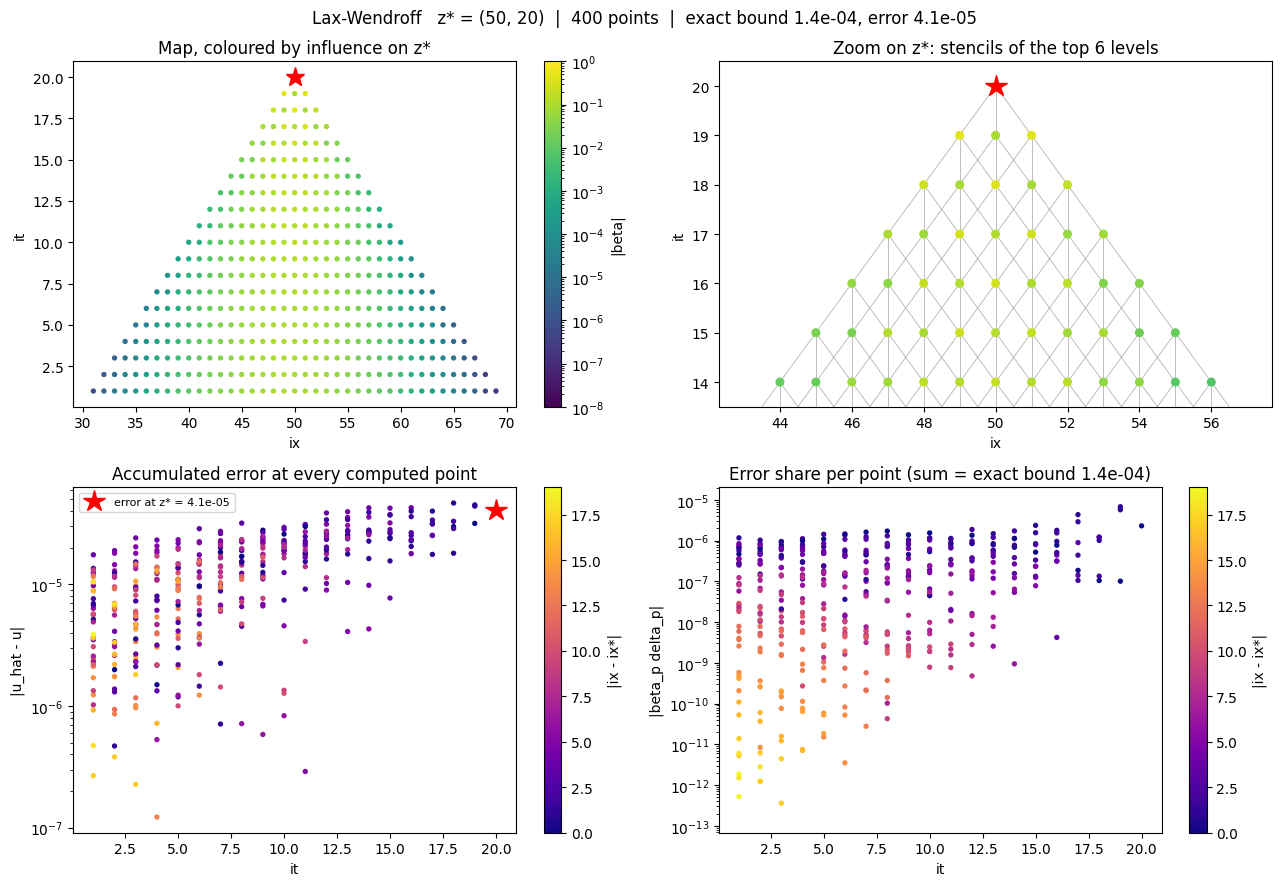

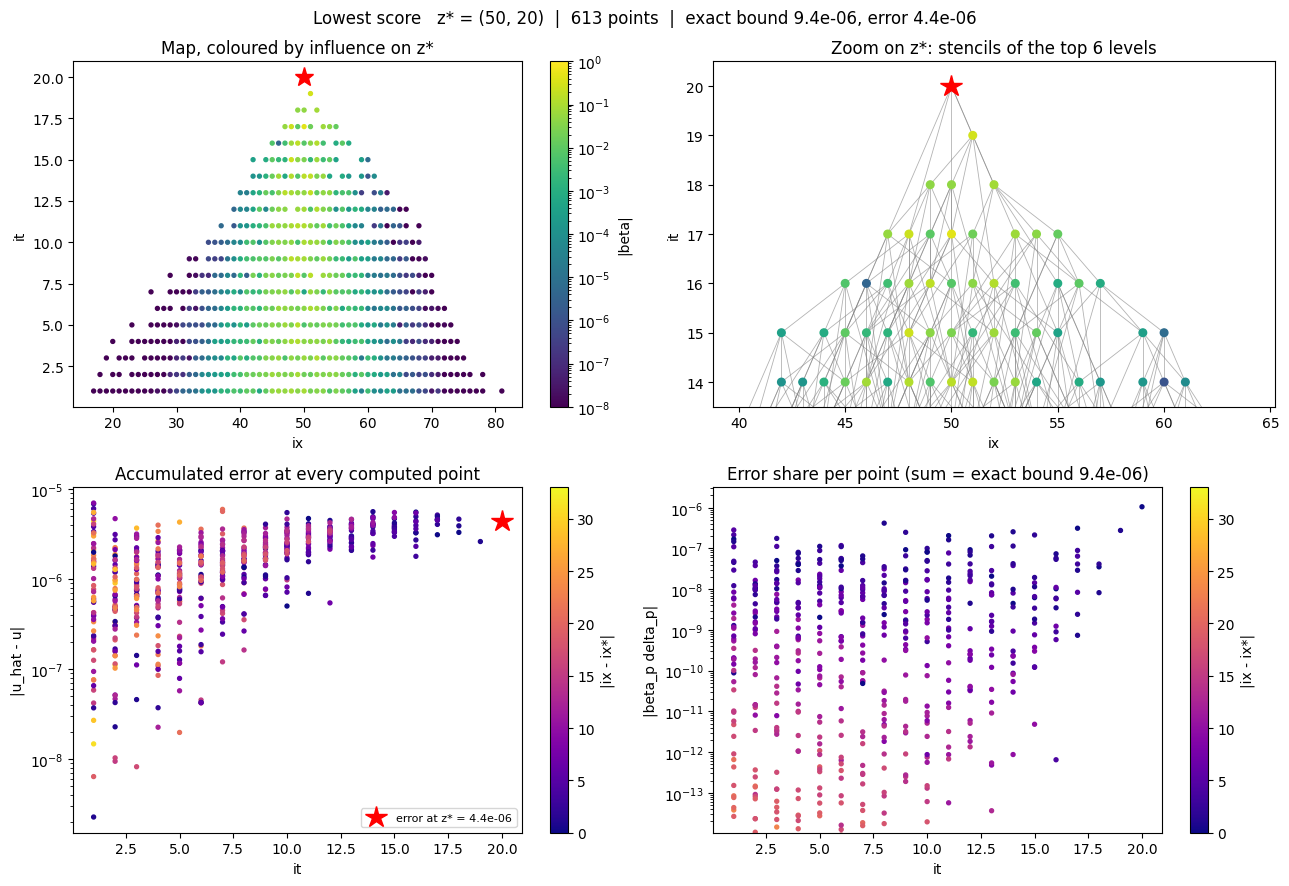

In [11]:
# ── One figure for any finished map (used for the baselines and the training videos) ──
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None):
    """2x2: the map coloured by influence | zoom on z* with stencils | accumulated error | error share per point.
    u_true is used ONLY for the last two panels. Saves to `path` if given, otherwise shows."""
    z, rep = m["z_star"], report(m)
    U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
    pts = list(m["stencil"])
    P = np.array(pts)
    beta = np.array([abs(m["beta"][p]) for p in pts])
    share = np.array([abs(m["beta"][p] * (U(p) - sum(wq * U(q) for q, wq in zip(*m["stencil"][p])))) for p in pts])
    u_hat = evaluate(m)

    fig, ((a1, a2), (a3, a4)) = plt.subplots(2, 2, figsize=(13, 9))

    # (1) the whole map, coloured by influence on z*
    sc = a1.scatter(P[:, 0], P[:, 1], c=beta, s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    a1.plot(*z, 'r*', ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("Map, coloured by influence on z*")

    # (2) zoom on z*: the stencils of the top levels
    top = [p for p in pts if p[1] >= z[1] - 2 * K_T]
    for p in top:
        for q in m["stencil"][p][0]:
            a2.plot([p[0], q[0]], [p[1], q[1]], '-', color='gray', lw=0.6, alpha=0.6)
    T_ = np.array(top)
    a2.scatter(T_[:, 0], T_[:, 1], c=[abs(m["beta"][p]) for p in top], s=30, cmap="viridis", norm=LogNorm(1e-8, 1), zorder=3)
    a2.plot(*z, 'r*', ms=16, zorder=4)
    a2.set_ylim(z[1] - 2 * K_T - 0.5, z[1] + 0.5)
    a2.set_xlabel("ix"); a2.set_ylabel("it"); a2.set_title(f"Zoom on z*: stencils of the top {2 * K_T} levels")

    # (3) accumulated error: |u_hat - u| at every computed point
    acc = np.array([abs(u_hat[p] - U(p)) for p in pts])
    sc = a3.scatter(P[:, 1], np.maximum(acc, 1e-16), c=np.abs(P[:, 0] - z[0]), s=8, cmap="plasma")
    a3.plot(z[1], rep["error"], 'r*', ms=16, label=f"error at z* = {rep['error']:.1e}")
    fig.colorbar(sc, ax=a3, label="|ix - ix*|")
    a3.set_yscale("log"); a3.set_xlabel("it"); a3.set_ylabel("|u_hat - u|"); a3.legend(fontsize=8)
    a3.set_title("Accumulated error at every computed point")

    # (4) where the error comes from: |beta_p delta_p| for every point
    sc = a4.scatter(P[:, 1], np.maximum(share, 1e-16), c=np.abs(P[:, 0] - z[0]), s=8, cmap="plasma")
    fig.colorbar(sc, ax=a4, label="|ix - ix*|")
    a4.set_yscale("log"); a4.set_ylim(max(share.max() * 1e-8, 1e-16), share.max() * 3)
    a4.set_xlabel("it"); a4.set_ylabel("|beta_p delta_p|")
    a4.set_title(f"Error share per point (sum = exact bound {rep['bound']:.1e})")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points  |  exact bound {rep['bound']:.1e}, error {rep['error']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

plot_map(build_map((50, 20), lw), "Lax-Wendroff")
plot_map(build_map((50, 20), lowest_score), "Lowest score")

### Training helpers and callbacks
- `make_env`: one training environment (with the action mask and the episode monitor).
- `run_policy`: one episode where the policy takes its most likely pick every time; returns the finished map.
- `MapLogCallback`: logs points, score sum (both relative to LW) and the finish rate of the training episodes to TensorBoard.
- `SnapshotCallback`: every `every` steps, runs the current policy on one query, saves its map figure (cell 9) and keeps its numbers. These images become the training-progress video.

All take an environment class (`env_cls`), so the same helpers serve the multi-query environment later.
Check: a tiny run (2 environments, 2048 steps) to see that everything connects.

In [29]:
# ── Helpers for training: environment factory and one greedy run of a trained policy ──
def make_env(queries, lam, seed, env_cls=MapEnv):
    def _init():
        env = Monitor(ActionMasker(env_cls(queries=queries, lam=lam), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam=lam)
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: log map numbers of every finished training episode (mean of the last 100) ──
class MapLogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.hist = {"points_ratio": [], "score_ratio": [], "finished": []}

    def _on_step(self):
        for info in self.locals["infos"]:
            if "points_ratio" in info:                              # only at the end of an episode
                for k in self.hist:
                    self.hist[k].append(float(info[k]))
        for k, v in self.hist.items():
            if v:
                self.logger.record(f"map/{k}", np.mean(v[-100:]))
        return True

# ── Callback 2: every `every` steps, run the current policy on z_plot, save the figure and the numbers ──
class SnapshotCallback(BaseCallback):
    def __init__(self, z_plot, lam, every, img_dir, env_cls=MapEnv):
        super().__init__()
        self.z_plot, self.lam, self.every, self.img_dir, self.env_cls = z_plot, lam, every, img_dir, env_cls
        self.last, self.hist, self.episodes = -every, [], 0

    def _on_step(self):
        self.episodes += sum("episode" in info for info in self.locals["infos"])   # maps finished in training
        if self.num_timesteps - self.last >= self.every:
            self.last = self.num_timesteps
            env = run_policy(self.model, self.z_plot, self.lam, self.env_cls)
            if env.info["finished"]:
                rep = report(env.m)
                plot_map(env.m, f"step {self.num_timesteps:,}  ({self.episodes} maps)  |  return {env.ret:.2f}",
                         os.path.join(self.img_dir, f"map_{self.num_timesteps:09d}.png"))
            else:
                rep = {"points": env.info["points"], "error": np.nan, "bound": np.nan}
            self.hist.append({"step": self.num_timesteps, "episodes": self.episodes, "return": env.ret, **rep})
            print(f"step {self.num_timesteps:>10,} | {self.episodes:5d} maps: return {env.ret:7.2f} | "
                  f"{rep['points']} points | bound {rep['bound']:.1e} | finished {env.info['finished']}")
        return True
    

### Training
MaskablePPO with $\gamma=1$ and `gae_lambda=1.0`: each pick is judged by the actual return of the rest of the episode.
Everything a run produces goes into one folder:
`runs{month}-{day}/{run_name}/config.json` (all settings, including the guess and the score), and for each seed: `images/` (snapshot figures + final map), `checkpoints/` (models), `logs/` (TensorBoard), `snapshots.json` (return, points, error, bound at every snapshot).
The stencil cache is not copied to the 12 workers (about 125 MB each); every worker fills its own in about 25 s.

In [18]:
import json
from stable_baselines3.common.callbacks import CheckpointCallback

# ── Training settings ──
QUERIES   = [(50, 20)]          # training queries z*
Z_PLOT    = (50, 20)            # query used for the snapshots / video
LAM       = 1.0                 # price of one new point (in units of LW's point count)
SEEDS     = [1]
TOTAL     = 5_000_000           # environment steps (= picks) per seed
N_ENVS    = 12
SNAP_EVERY, CKPT_EVERY = 100_000, 500_000
PPO_KW    = dict(n_steps=256, batch_size=256, gamma=1.0, gae_lambda=1.0, learning_rate=3e-4, ent_coef=0.0)

# ── Run folder: everything this run produces goes here ──
run_name = f"burgers_single_z{Z_PLOT[0]}-{Z_PLOT[1]}_lam{LAM:g}_R{R_X}K{K_T}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
os.makedirs(run_dir, exist_ok=True)
config = dict(queries=QUERIES, z_plot=Z_PLOT, lam=LAM, seeds=SEEDS, total=TOTAL, n_envs=N_ENVS,
              window=dict(R_X=R_X, K_T=K_T, N_NB=N_NB), admissible=dict(COND_MAX=COND_MAX, W_MAX=W_MAX),
              pde=dict(name="Burgers", alpha=alpha, nx=nx, nt=nt), guess=dict(K_COARSE=K_COARSE, points=G_COARSE, A_STEP=A_STEP),
              score="Burgers Taylor polynomial up to weight 4, guessed derivatives", ppo=PPO_KW, date=str(date.today()))
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(config, f, indent=2)
print("run folder:", run_dir)

# the reference (LW) maps are small: fill them once here. The stencil cache is NOT copied to the workers
# (about 125 MB each); every worker fills its own in about 25 s.
for z in QUERIES:
    reference(z)
_sets_cache.clear(); _w_cache.clear()

for seed in SEEDS:
    seed_dir = os.path.join(run_dir, f"seed{seed}")
    img_dir, ckpt_dir = os.path.join(seed_dir, "images"), os.path.join(seed_dir, "checkpoints")
    os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
    print(f"\n{'#' * 40}\nSEED {seed}\n{'#' * 40}")

    vec = SubprocVecEnv([make_env(QUERIES, LAM, seed=100 * seed + i) for i in range(N_ENVS)])
    model = MaskablePPO("MlpPolicy", vec, seed=seed, verbose=0, device="cpu",
                        tensorboard_log=os.path.join(seed_dir, "logs"), **PPO_KW)
    snap_cb = SnapshotCallback(Z_PLOT, LAM, every=SNAP_EVERY, img_dir=img_dir)
    t0 = time.time()
    model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
                callback=[MapLogCallback(), snap_cb,
                          CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
    vec.close()
    print(f"training time: {(time.time() - t0) / 60:.0f} min")

    # save: final model, the snapshot numbers, and the final map figure
    model.save(os.path.join(ckpt_dir, "ppo_final"))
    with open(os.path.join(seed_dir, "snapshots.json"), "w") as f:
        json.dump(snap_cb.hist, f, indent=1, default=float)
    env = run_policy(model, Z_PLOT, LAM)
    plot_map(env.m, f"final  |  return {env.ret:.2f}", os.path.join(img_dir, "map_final.png"))
    print("final:", {k: (f"{v:.2e}" if isinstance(v, float) else v) for k, v in report(env.m).items()},
          f"| return {env.ret:.2f}  (LW = {-1 - LAM * (reference(Z_PLOT)[1] - 1) / reference(Z_PLOT)[1]:.2f})")

run folder: runs10-7\burgers_single_z50-20_lam1_R3K3

########################################
SEED 1
########################################
step         12 |     0 maps: return   -5.10 | 399 points | bound 5.6e-04 | finished True
step    100,020 |    24 maps: return   -3.47 | 553 points | bound 3.0e-04 | finished True
step    200,028 |    60 maps: return   -3.35 | 585 points | bound 2.7e-04 | finished True
step    300,036 |    98 maps: return   -2.01 | 402 points | bound 1.4e-04 | finished True
step    400,044 |   136 maps: return   -2.12 | 398 points | bound 1.6e-04 | finished True
step    500,052 |   181 maps: return   -2.03 | 367 points | bound 1.6e-04 | finished True
step    600,060 |   232 maps: return   -1.85 | 383 points | bound 1.2e-04 | finished True
step    700,068 |   285 maps: return   -1.82 | 372 points | bound 1.3e-04 | finished True
step    800,076 |   341 maps: return   -1.77 | 352 points | bound 1.3e-04 | finished True
step    900,084 |   397 maps: return   -1.69 | 

### Videos and learning curves
From a finished run folder (no training here): the learning curves against the baselines, the training-progress video (the snapshot figures in order), and two build videos (the trained policy and Lax–Wendroff building their maps from $z^*$ down).

LW          : return -2.00, 400 points, bound 1.4e-04
lowest score: return -1.54, 613 points, bound 9.4e-06
agent       : return -1.02, 242 points, bound 6.0e-05, error 2.2e-05


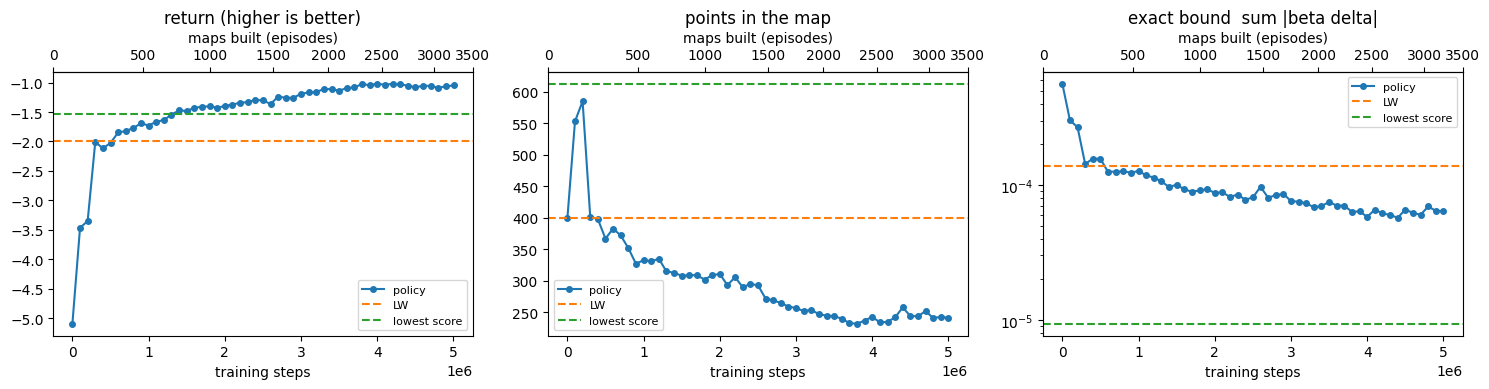

52 frames: map_000000012.png ... map_final.png
saved: runs10-7\burgers_single_z50-20_lam1_R3K3\seed1\images\training_progress.mp4
120 frames, 242 points | saved: runs10-7\burgers_single_z50-20_lam1_R3K3\seed1\images\build_final.mp4
120 frames, 400 points | saved: runs10-7\burgers_single_z50-20_lam1_R3K3\seed1\images\build_LW.mp4


'runs10-7\\burgers_single_z50-20_lam1_R3K3\\seed1\\images\\build_LW.mp4'

In [19]:
from map_progress_video import make_progress_video
from map_build_video import make_build_video
from learning_curves import plot_learning_curves

seed_dir = os.path.join(run_dir, f"seed{SEEDS[0]}")            # or paste the path of a copied run folder
img_dir  = os.path.join(seed_dir, "images")
model    = MaskablePPO.load(os.path.join(seed_dir, "checkpoints", "ppo_final"))

def baseline(rule):
    """Return, points and exact bound of a fixed rule's map, on the same reward as the agent."""
    mm, (B_ref, N_ref) = build_map(Z_PLOT, rule), reference(Z_PLOT)
    rep = report(mm)
    B = sum(abs(mm["beta"][p]) * point_score(p, *mm["stencil"][p]) for p in mm["stencil"])
    return {"return": -B / B_ref - LAM * (rep["points"] - 1) / N_ref, "points": rep["points"], "bound": rep["bound"]}

baselines = {"LW": baseline(lw), "lowest score": baseline(lowest_score)}
for name, b in baselines.items():
    print(f"{name:12s}: return {b['return']:.2f}, {b['points']} points, bound {b['bound']:.1e}")
env = run_policy(model, Z_PLOT, LAM)
rep = report(env.m)
print(f"{'agent':12s}: return {env.ret:.2f}, {rep['points']} points, bound {rep['bound']:.1e}, error {rep['error']:.1e}")

plot_learning_curves(os.path.join(seed_dir, "snapshots.json"), baselines)
make_progress_video(img_dir, fps=2)
make_build_video(env.m, os.path.join(img_dir, "build_final.mp4"), is_known, title=f"trained policy, seed {SEEDS[0]}")
make_build_video(build_map(Z_PLOT, lw), os.path.join(img_dir, "build_LW.mp4"), is_known, title="Lax-Wendroff")

### Comparison: accuracy vs evaluated points
Every method at the same $z^*$, judged by its true error against the number of points it computes.
- **Classical schemes** (FD-3, LW, FD-5 + RK4, Crank–Nicolson) run on grids refined 1–4×, giving one curve each. For Burgers each grid point uses its own value as the speed; Crank–Nicolson takes it from the previous step (linearised CN).
- **Map methods** run on the base grid, one point each: filled marker = true error, open circle = exact bound $\sum|\beta\delta|$. Each also pays for the part of the coarse guess it uses: the coarse levels up to the first one at or after $t^*$ (the later levels serve other queries).
  - **agent (PPO)**, the trained policy;
  - **best fixed stencil**: brute force over every admissible stencil at $z^*$, each used at every point where it is admissible (elsewhere the lowest-score stencil, counted), ranked by the agent's return. The test of "is RL needed?";
  - **lowest score**, **greedy** (best one-step reward: accuracy and new points), **random**.

**Evaluated points** = grid values actually computed in $z^*$'s dependency cone (RK4: ×4 for its 4 stages; Crank–Nicolson: the whole row at every step, since it is implicit).
The brute force takes about 7 minutes; set `REDO_SEARCH = False` to reuse `rows` from an earlier run.

In [30]:
from scipy.linalg import solve_banded
from joblib import Parallel, delayed

Z_CMP = Z_PLOT
x_star, t_star = Z_CMP[0] * dx, Z_CMP[1] * dt
REDO_SEARCH = True                     # False: reuse `rows` (the brute-force result) if it already exists

# ── Classical schemes on their own grids (refined k = 1..4, r = alpha dt/dx^2 kept fixed); Burgers: speed a(u) per point ──
def classical(scheme, k):
    """Error at z* and evaluated points (grid values in z*'s dependency cone) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2          # CN is implicit: 4x bigger steps
    ix, steps = Z_CMP[0] * k, round(t_star / tau_k)
    u = u_true(np.arange(n) * h, 0.0)
    r = alpha * tau_k / h**2
    d2 = lambda v: np.r_[0, v[2:] - 2 * v[1:-1] + v[:-2], 0]
    d1 = lambda v: np.r_[0, v[2:] - v[:-2], 0] / 2
    def d4(v):                                                      # 4th-order u_xx*h^2 and u_x*h, 2nd order next to the walls
        a2, a1 = d2(v), d1(v)
        a2[2:-2] = (-v[4:] + 16 * v[3:-1] - 30 * v[2:-2] + 16 * v[1:-3] - v[:-4]) / 12
        a1[2:-2] = (-v[4:] + 8 * v[3:-1] - 8 * v[1:-3] + v[:-4]) / 12
        return a2, a1
    for _ in range(steps):
        nu = a(u) * tau_k / h                                       # local speed at every grid point
        if scheme == "FD-3":
            u = u + r * d2(u) - nu * d1(u)
        elif scheme == "LW":
            u = u + (r + nu**2 / 2) * d2(u) - nu * d1(u)
        elif scheme == "FD-5 + RK4":
            f = lambda v: (lambda a2, a1: r * a2 - a(v) * tau_k / h * a1)(*d4(v))
            k1 = f(u); k2 = f(u + k1 / 2); k3 = f(u + k2 / 2); k4 = f(u + k3)
            u = u + (k1 + 2 * k2 + 2 * k3 + k4) / 6
        elif scheme == "CN":                                        # speed taken from the previous step (linearised CN)
            lo, di, up = -r / 2 - nu[1:-1] / 4, (1 + r) * np.ones(n - 2), -r / 2 + nu[1:-1] / 4
            ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], di, lo[1:]
            u = np.r_[0, solve_banded((1, 1), ab, (u + r / 2 * d2(u) - nu / 2 * d1(u))[1:-1]), 0]
        u[0] = u[-1] = 0.0
    err = abs(u[ix] - u_true(x_star, t_star)[0])
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8}.get(scheme)       # cone half-width growth per step
    if spread is None:                                              # CN couples the whole row at every step
        pts = (n - 2) * steps
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        if scheme == "FD-5 + RK4":
            pts *= 4                                                # 4 stage evaluations per point and step
    return pts, err

curves = {s: np.array([classical(s, k) for k in (1, 2, 3, 4)]) for s in ["FD-3", "LW", "FD-5 + RK4", "CN"]}

# ── Map rules on the base grid ──
def greedy(m, p):
    """Each point takes the stencil with the best one-step reward: accuracy AND new points (the agent's reward)."""
    B_ref, N_ref = reference(m["z_star"])
    sets, _, sc = admissible(p)
    cost = [abs(m["beta"][p]) * s_ / B_ref
            + LAM * sum(1 for q in {place(p, k) for k in st} if not is_known(q) and q not in m["beta"]) / N_ref
            for st, s_ in zip(sets, sc)]
    return [place(p, k) for k in sets[int(np.argmin(cost))]]

def fixed_rule(s):
    """The same window cells s at every point where they are admissible; elsewhere the point's lowest-score stencil.
    For Burgers admissibility depends on the local speed, so the fallback can also happen in the interior (counted)."""
    allowed, count = {}, {"fixed": 0, "fallback": 0}
    def choose(m, p):
        key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
        if key not in allowed:
            allowed[key] = set(admissible(p)[0])
        use = s in allowed[key]
        count["fixed" if use else "fallback"] += 1
        return [place(p, k) for k in s] if use else lowest_score(m, p)
    choose.count = count
    return choose

def map_return(m, z, lam):
    B_ref, N_ref = reference(z)
    B = sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])
    return -B / B_ref - lam * (len(m["stencil"]) - 1) / N_ref

# ── Best fixed stencil: brute force over every admissible stencil at z*, ranked by the agent's return ──
# run in parallel; the stencil cache is cleared first so it is not copied to every worker (each fills its own)
def fixed_chunk(chunk, z, lam):
    return [(s, map_return(m, z, lam), len(m["stencil"])) for s in chunk for m in [build_map(z, fixed_rule(s))]]

if REDO_SEARCH or "rows" not in globals():
    interior = admissible(Z_CMP)[0]
    _sets_cache.clear(); _w_cache.clear()
    t0 = time.time()
    parts = Parallel(n_jobs=N_ENVS)(delayed(fixed_chunk)([interior[i] for i in idx], Z_CMP, LAM)
                                      for idx in np.array_split(np.arange(len(interior)), N_ENVS))
    rows = sorted((r for part in parts for r in part), key=lambda r: -r[1])
    print(f"{len(rows)} fixed stencils in {time.time() - t0:.0f} s")
else:
    print(f"reusing the earlier brute force ({len(rows)} fixed stencils)")

# ── All map methods at z* ──
best_rule = fixed_rule(rows[0][0])
agent = run_policy(model, Z_CMP, LAM)
maps = {"agent (PPO)": agent.m, "best fixed stencil": build_map(Z_CMP, best_rule),
        "lowest score": build_map(Z_CMP, lowest_score), "greedy": build_map(Z_CMP, greedy)}
rnd = MapEnv([Z_CMP], lam=LAM); rnd.reset(seed=0); rng, done = np.random.default_rng(0), False
while not done:
    _, _, done, _, _ = rnd.step(rng.choice(np.flatnonzero(rnd.action_masks())))
maps["random"] = rnd.m

# the guess is only needed up to the first coarse level at or after t* (its later levels serve other queries)
guess_cost = (len(xc) - 2) * int(np.ceil(t_star / tau))
pts_map = {name: {**report(mm), "return": map_return(mm, Z_CMP, LAM)} for name, mm in maps.items()}
for rep in pts_map.values():
    rep["map points"] = rep["points"]
    rep["points"] += guess_cost

print(f"best fixed stencil {[WINDOW[k] for k in rows[0][0]]}: used at {best_rule.count['fixed']} points, "
      f"lowest-score fallback at {best_rule.count['fallback']}")
print(f"fixed stencils that beat the agent: {sum(r[1] > agent.ret for r in rows)} of {len(rows)}")
print(f"guess cost for this query: {guess_cost} points ({int(np.ceil(t_star / tau))} coarse level(s) x {len(xc) - 2} interior points)\n")
for s, cv in curves.items():
    print(f"{s:12s}: " + " | ".join(f"{int(p):6d} pts {e:.1e}" for p, e in cv))
for name, rep in pts_map.items():
    print(f"{name:18s}: return {rep['return']:6.2f} | {rep['map points']:4d} map + {guess_cost} guess = {rep['points']:5d} pts | "
          f"error {rep['error']:.1e} | exact bound {rep['bound']:.1e}")

fig, ax = plt.subplots(figsize=(9, 6))
for i, (s, cv) in enumerate(curves.items()):
    ax.loglog(cv[:, 0], cv[:, 1], "o-", color=f"C{i}", label=f"{s} (grid refined 1-4x)")
marks = {"agent (PPO)": "r*", "best fixed stencil": "gP", "lowest score": "bD", "greedy": "mv", "random": "kx"}
for name, rep in pts_map.items():
    ax.loglog(rep["points"], rep["error"], marks[name], ms=13, label=f"{name}: error")
    ax.loglog(rep["points"], rep["bound"], marks[name][0] + "o", ms=9, mfc="none")
ax.plot([], [], "ko", mfc="none", label="open circle: exact bound of a map method")
ax.set_xlabel(f"evaluated points (map methods: + {guess_cost} for the coarse guess)"); ax.set_ylabel("|error at z*|")
ax.set_title(f"Burgers: accuracy vs evaluated points at z* = {Z_CMP}"); ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

NameError: name 'Z_PLOT' is not defined

# Lambda Sweep

In [23]:
# ══ λ sweep · Cell A: helpers ══
import json
import pandas as pd
from stable_baselines3.common.callbacks import CheckpointCallback
a = lambda u: u          # restore the Burgers speed (Cell B overwrote it)
# exact values on the grid up to it = 100, once (u_true ONLY for reporting)
U_GRID = np.array([u_true(x_grid, it * dt) for it in range(101)])   # (it, ix)
Ug = lambda q: U_GRID[q[1], q[0]]

def report_fast(m):
    """(points, true error at z*, exact bound sum |beta delta|), from the precomputed exact grid."""
    z, u_hat = m["z_star"], evaluate(m)
    bound = sum(abs(m["beta"][p] * (Ug(p) - w @ np.array([Ug(q) for q in nbs]))) for p, (nbs, w) in m["stencil"].items())
    return len(m["stencil"]), abs(Ug(z) - u_hat[z]), bound

def score_sum(m):
    """B = sum |beta_p| s_p: the accuracy part of the return (independent of λ)."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """Best one-step reward at every point, vectorised over all admissible stencils at p."""
    def choose(m, p):
        B_ref, N_ref = reference(m["z_star"])
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / B_ref + lam * (uses.astype(float) @ new) / N_ref   # count of new points
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

def map_return(m, z, lam):
    B_ref, N_ref = reference(z)
    return -score_sum(m) / B_ref - lam * (len(m["stencil"]) - 1) / N_ref

# check: greedy at (50, 20), λ = 1 must give -0.51 with 181 points
m = build_map((50, 20), greedy_rule(1.0))
print(f"greedy check (50,20), λ=1: return {map_return(m, (50, 20), 1.0):.3f}, {len(m['stencil'])} points")

greedy check (50,20), λ=1: return -0.506, 181 points


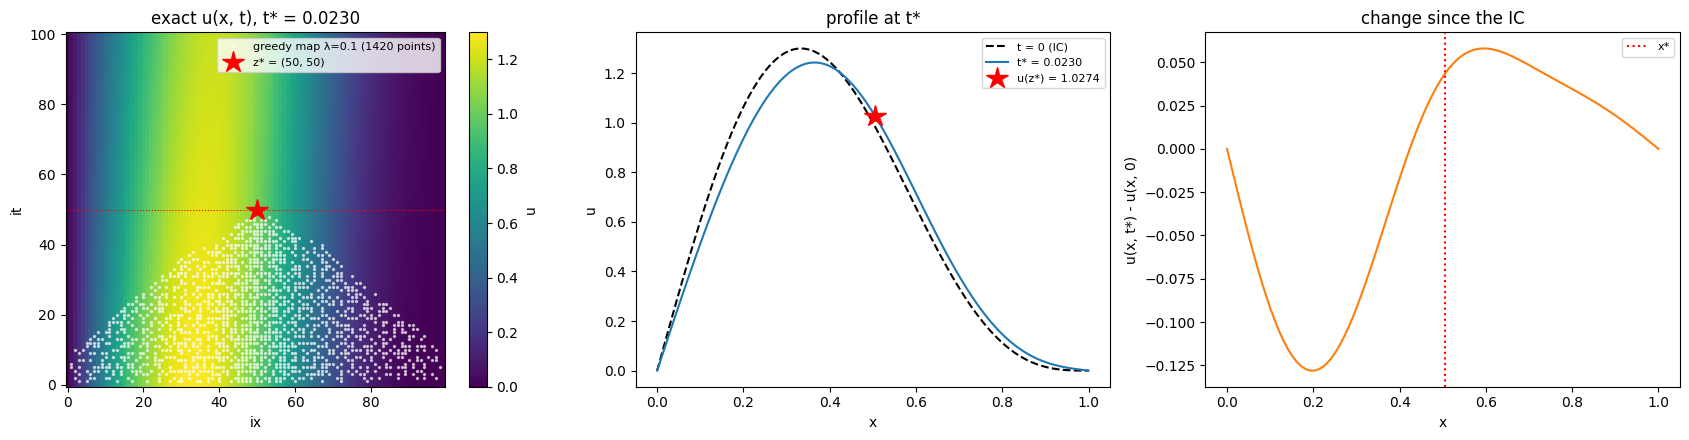

z* = (50, 50): x* = 0.505, t* = 0.0230 (4.6% of T), u(z*) = 1.02737
LW map 2499 points | greedy λ=0.1: 1420 points


In [24]:
# ══ λ sweep · before D: the true solution around the training query z* = (50, 50) ══
_z = (50, 50)
_it_max = 2 * _z[1]                                                   # show up to twice t*
_U = np.array([u_true(x_grid, _it * dt) for _it in range(_it_max + 1)])   # (it, ix), u_true ONLY for this picture

_fig, _ax = plt.subplots(1, 3, figsize=(17, 4.5))

# (1) u(x, t) near the query, with z* and the greedy map at λ = 0.1 (what PPO has to beat)
_im = _ax[0].pcolormesh(np.arange(nx), np.arange(_it_max + 1), _U, shading="auto", cmap="viridis")
_fig.colorbar(_im, ax=_ax[0], label="u")
_mg = build_map(_z, greedy_rule(0.1))
_P = np.array(list(_mg["stencil"]))
_ax[0].scatter(_P[:, 0], _P[:, 1], s=2, c="w", alpha=0.6, label=f"greedy map λ=0.1 ({len(_P)} points)")
_ax[0].plot(*_z, "r*", ms=16, label=f"z* = {_z}")
_ax[0].axhline(_z[1], color="r", ls=":", lw=0.8)
_ax[0].set_xlabel("ix"); _ax[0].set_ylabel("it"); _ax[0].legend(fontsize=8, loc="upper right")
_ax[0].set_title(f"exact u(x, t), t* = {_z[1] * dt:.4f}")

# (2) the profile at t = 0 and at t*, with the query point
_ax[1].plot(x_grid, _U[0], "k--", label="t = 0 (IC)")
_ax[1].plot(x_grid, _U[_z[1]], "C0", label=f"t* = {_z[1] * dt:.4f}")
_ax[1].plot(_z[0] * dx, _U[_z[1], _z[0]], "r*", ms=16, label=f"u(z*) = {_U[_z[1], _z[0]]:.4f}")
_ax[1].set_xlabel("x"); _ax[1].set_ylabel("u"); _ax[1].legend(fontsize=8); _ax[1].set_title("profile at t*")

# (3) how much u changes between t = 0 and t*: the change the map has to capture
_ax[2].plot(x_grid, _U[_z[1]] - _U[0], "C1")
_ax[2].axvline(_z[0] * dx, color="r", ls=":", label="x*")
_ax[2].set_xlabel("x"); _ax[2].set_ylabel("u(x, t*) - u(x, 0)"); _ax[2].legend(fontsize=8)
_ax[2].set_title("change since the IC")

plt.tight_layout(); plt.show()
print(f"z* = {_z}: x* = {_z[0] * dx:.3f}, t* = {_z[1] * dt:.4f} ({_z[1] / (nt - 1):.1%} of T), u(z*) = {_U[_z[1], _z[0]]:.5f}")
print(f"LW map {reference(_z)[1]} points | greedy λ=0.1: {len(_P)} points")

In [35]:
# ── Fix: solve the weights in the window order, so admissibility can't flip with the pick order ──
_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs, with p's guessed speed; None if not admissible.
    Solved in a canonical order (the window order: latest level first, then left to right), so the
    admissibility test is bit-identical to admissible(p) whatever order the cells were picked in."""
    offs  = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    order = sorted(range(len(offs)), key=lambda i: (-offs[i][1], offs[i][0]))
    key   = (tuple(offs[i] for i in order), a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in key[0]]) * dx, np.array([o[1] for o in key[0]]) * dt, key[1])
    w = _w_cache[key]
    if w is None:
        return None
    out = np.empty(len(offs)); out[order] = w                  # back to the order of nbs
    return out

In [36]:
# ══ λ sweep · Cell D: PPO (ranked env) at one query, one model per λ ══
LAMS_TRAIN = [0.003, 0.01, 0.03, 0.1]
Z_TRAIN    = (50, 50)
SEED       = 1
TOTAL      = 8_000_000               # picks per λ
N_ENVS     = 12
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW     = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=1.0, learning_rate=3e-4, ent_coef=0.0)
ENV_CLS    = MapEnvRanked

B_ref, N_ref = reference(Z_TRAIN)
sweep_root = os.path.join(f"runs{date.today().month}-{date.today().day}", f"lamsweep_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_R{R_X}K{K_T}")
os.makedirs(sweep_root, exist_ok=True)
print(f"z* = {Z_TRAIN}: LW map {N_ref} points | λ values: {LAMS_TRAIN}")

results = []
for lam in LAMS_TRAIN:
    run_dir = os.path.join(sweep_root, f"lam{lam:g}")
    img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
    os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(dict(z=Z_TRAIN, lam=lam, seed=SEED, total=TOTAL, n_envs=N_ENVS, ppo=PPO_KW, env="ranked",
                       window=dict(R_X=R_X, K_T=K_T, N_NB=N_NB), pde=dict(name="Burgers", alpha=alpha, nx=nx, nt=nt),
                       date=str(date.today())), f, indent=2)

    # greedy at this λ: the number to beat
    mg = build_map(Z_TRAIN, greedy_rule(lam))
    ng, errg, bndg = report_fast(mg)
    ret_g = map_return(mg, Z_TRAIN, lam)
    print(f"\n{'#' * 40}\nλ = {lam}   (greedy: return {ret_g:.3f}, {ng} points, bound {bndg:.1e})\n{'#' * 40}")

    _sets_cache.clear(); _w_cache.clear()                        # don't ship the big caches to the workers
    vec = SubprocVecEnv([make_env([Z_TRAIN], lam, seed=100 * SEED + i, env_cls=ENV_CLS) for i in range(N_ENVS)])
    model = MaskablePPO("MlpPolicy", vec, seed=SEED, verbose=0, device="cpu",
                        tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)
    snap_cb = SnapshotCallback(Z_TRAIN, lam, every=SNAP_EVERY, img_dir=img_dir, env_cls=ENV_CLS)
    t0 = time.time()
    model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
                callback=[MapLogCallback(), snap_cb,
                          CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
    vec.close()
    minutes = (time.time() - t0) / 60
    model.save(os.path.join(ckpt_dir, "ppo_final"))
    with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
        json.dump(snap_cb.hist, f, indent=1, default=float)

    # final policy vs greedy
    env = run_policy(model, Z_TRAIN, lam, ENV_CLS)
    plot_map(env.m, f"PPO, λ = {lam}  |  return {env.ret:.2f}", os.path.join(img_dir, "map_final.png"))
    n, err, bnd = report_fast(env.m)
    results.append(dict(lam=lam, ppo_ret=env.ret, ppo_points=n, ppo_bound=bnd, ppo_error=err,
                        greedy_ret=ret_g, greedy_points=ng, greedy_bound=bndg, greedy_error=errg,
                        minutes=minutes, episodes=snap_cb.episodes))
    pd.DataFrame(results).to_csv(os.path.join(sweep_root, "ppo_vs_greedy.csv"), index=False)   # saved after every λ
    print(f"λ = {lam}: PPO return {env.ret:.3f} ({n} pts, bound {bnd:.1e}) | greedy {ret_g:.3f} ({ng} pts, bound {bndg:.1e}) "
          f"| {snap_cb.episodes} maps in {minutes:.0f} min")

res = pd.DataFrame(results)
res["gap"] = res.ppo_ret - res.greedy_ret                       # > 0: PPO beats greedy
print(res[["lam", "ppo_ret", "greedy_ret", "gap", "ppo_points", "greedy_points", "ppo_bound", "greedy_bound", "episodes", "minutes"]].round(4))

z* = (50, 50): LW map 2499 points | λ values: [0.003, 0.01, 0.03, 0.1]

########################################
λ = 0.003   (greedy: return -0.007, 1552 points, bound 3.1e-05)
########################################
step         12 |     0 maps: return   -1.86 | 3110 points | bound 5.6e-04 | finished True
step    250,020 |    12 maps: return   -3.31 | 2929 points | bound 1.0e-03 | finished True
step    500,028 |    24 maps: return   -1.87 | 2790 points | bound 5.6e-04 | finished True
step    750,036 |    36 maps: return   -0.68 | 3155 points | bound 2.1e-04 | finished True
step  1,000,044 |    54 maps: return   -0.36 | 3625 points | bound 1.2e-04 | finished True
step  1,250,052 |    72 maps: return   -0.15 | 3288 points | bound 6.6e-05 | finished True
step  1,500,060 |    84 maps: return   -0.11 | 3455 points | bound 5.9e-05 | finished True
step  1,750,068 |    97 maps: return   -0.06 | 3587 points | bound 4.4e-05 | finished True
step  2,000,076 |   114 maps: return   -0.05 | 3429 po

RETURN (higher is better)
lam            0.003   0.010   0.030   0.100
method                                      
lowest score -0.0074 -0.0162 -0.0414 -0.1293
LW map       -1.0030 -1.0100 -1.0300 -1.1000
greedy       -0.0067 -0.0109 -0.0245 -0.0691
PPO          -0.0399 -0.0215 -0.0632 -0.1505

POINTS
lam            0.003   0.010   0.030   0.100
method                                      
lowest score  3141.0  3141.0  3141.0  3141.0
LW map        2499.0  2499.0  2499.0  2499.0
greedy        1552.0  1542.0  1529.0  1420.0
PPO           3150.0  2599.0  3117.0  2842.0

TRUE ERROR
lam             0.003    0.010    0.030    0.100
method                                          
lowest score  1.4e-05  1.4e-05  1.4e-05  1.4e-05
LW map        9.2e-05  9.2e-05  9.2e-05  9.2e-05
greedy        1.2e-05  1.2e-05  1.3e-05  1.3e-05
PPO           1.5e-05  1.6e-05  1.4e-05  1.3e-05


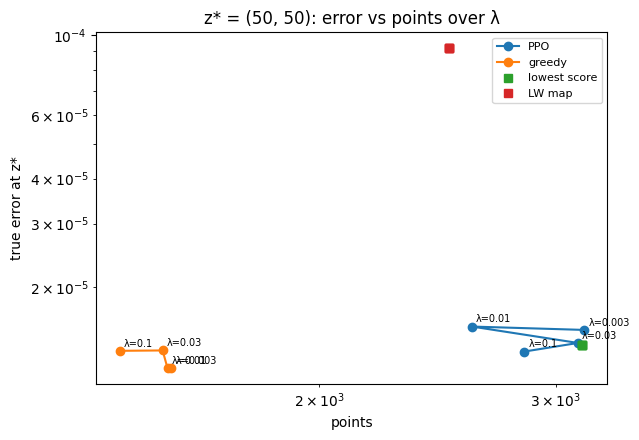

In [37]:
# ══ λ sweep · after D: every method at every λ, at Z_TRAIN ══
_rows = []
_maps = {"lowest score": build_map(Z_TRAIN, lowest_score), "LW map": build_map(Z_TRAIN, lw)}   # λ-independent maps
for lam in LAMS_TRAIN:
    _maps[f"greedy"] = build_map(Z_TRAIN, greedy_rule(lam))
    _model = MaskablePPO.load(os.path.join(sweep_root, f"lam{lam:g}", "checkpoints", "ppo_final"))
    _maps["PPO"] = run_policy(_model, Z_TRAIN, lam, ENV_CLS).m
    for name, mm in _maps.items():
        n, err, bnd = report_fast(mm)
        _rows.append(dict(lam=lam, method=name, ret=map_return(mm, Z_TRAIN, lam), points=n, error=err, bound=bnd))
cmp = pd.DataFrame(_rows)
cmp.to_csv(os.path.join(sweep_root, "all_methods.csv"), index=False)

print("RETURN (higher is better)")
print(cmp.pivot_table(index="method", columns="lam", values="ret", sort=False).round(4))
print("\nPOINTS");      print(cmp.pivot_table(index="method", columns="lam", values="points", sort=False))
print("\nTRUE ERROR");  print(cmp.pivot_table(index="method", columns="lam", values="error", sort=False).map(lambda v: f"{v:.1e}"))

# error vs points: each method traced over λ
_fig, _ax = plt.subplots(figsize=(6.5, 4.5))
for i, name in enumerate(["PPO", "greedy", "lowest score", "LW map"]):
    d = cmp[cmp.method == name].sort_values("lam")
    _ax.plot(d.points, d.error, "o-" if name in ("PPO", "greedy") else "s", color=f"C{i}", label=name)
    if name in ("PPO", "greedy"):
        for _, r_ in d.iterrows():
            _ax.annotate(f"λ={r_.lam:g}", (r_.points, r_.error), fontsize=7, xytext=(3, 3), textcoords="offset points")
_ax.set_xscale("log"); _ax.set_yscale("log"); _ax.set_xlabel("points"); _ax.set_ylabel("true error at z*")
_ax.set_title(f"z* = {Z_TRAIN}: error vs points over λ"); _ax.legend(fontsize=8)
plt.tight_layout(); plt.show()